# Task 2: Damped Harmonic Oscillator

## Setup and Network Architecture

In [144]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [145]:
seed = 42

rng = np.random.default_rng(seed)
torch.manual_seed(seed)
torch.set_default_dtype(torch.float64) # Make torch datatype match numpy default

In [146]:
class Net(nn.Module):
    def __init__(self, input_size=1, output_size=1, hidden_layers=[32, 32], activation=nn.Tanh):
        """
        input_size: int, number of features in input
        output_size: int, number of output neurons
        hidden_layers: list of ints, each int is the number of neurons in that hidden layer
        activation: nn.Module, activation function class (default nn.Tanh)
        """
        super(Net, self).__init__()

        layers = []

        # Input layer -> first hidden layer
        layers.append(nn.Linear(input_size, hidden_layers[0]))
        layers.append(activation())

        # Hidden layers
        for i in range(1, len(hidden_layers)):
            layers.append(nn.Linear(hidden_layers[i-1], hidden_layers[i]))
            layers.append(activation())

        # Output layer
        layers.append(nn.Linear(hidden_layers[-1], output_size))

        # Combine layers into a Sequential module
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

## Physical System and Exact Solution

In [147]:
# Define system parameters
t0 = 0.0
T = 1.0

m = 1 # mass
k = 500 # spring constant
mu = 5.0 # friction constant

d = mu/(2*m)
w0 = np.sqrt(k/m)
w = np.sqrt(w0**2 - d**2)

# Define initial conditions
x_t0_true = torch.tensor([[1.0]])
v_t0_true = torch.tensor([[0.0]])

# Closed from solution
phi = np.arctan(-d/w)
A = 1/(2*np.cos(phi))

x_sol = lambda t : np.exp(-d*t)*(2*A*np.cos(phi + w*t))

## Task 2.1 — Generate Training Data

In [148]:
# Generate datapoints
t_data = rng.uniform(low=0.0, high=0.5, size=10)
x_data = x_sol(t_data)

## Task 2.2 — Data-Only Neural Network

In [149]:
net = Net(1,1,[32]) # Initialize network

# Define optimizer
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

# number of training passses
num_epochs = 20_000
# store loss
train_losses = []

# training loop
for e in range(num_epochs):
    # get training input and expected output as torch Variables and make sure type is correct
    tr_input = torch.from_numpy(t_data).reshape(-1, 1)
    tr_targets = torch.from_numpy(x_data).reshape(-1, 1)
    
    # Reset gradients from the previous iteration
    optimizer.zero_grad()
    # predict by running forward pass
    tr_output = net(tr_input)
    # Compute mean squared error (MSE)
    tr_loss = F.mse_loss(tr_output, tr_targets)
    # compute gradients given loss
    tr_loss.backward()
    # update the parameters given the computed gradients
    optimizer.step()
    
    # store training loss
    train_losses.append(tr_loss.detach().numpy())
    
    if e % (num_epochs//10) == 0:
        print(f"Epoch {e}, Train Cost: {train_losses[-1]:.3f}")

Epoch 0, Train Cost: 0.703
Epoch 2000, Train Cost: 0.016
Epoch 4000, Train Cost: 0.015
Epoch 6000, Train Cost: 0.015
Epoch 8000, Train Cost: 0.014
Epoch 10000, Train Cost: 0.010
Epoch 12000, Train Cost: 0.001
Epoch 14000, Train Cost: 0.000
Epoch 16000, Train Cost: 0.000
Epoch 18000, Train Cost: 0.000


### Evaluation and Extrapolation

C:\Users\oloms\AppData\Local\Temp\ipykernel_18160\3175266171.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  x_sol = lambda t : np.exp(-d*t)*(2*A*np.cos(phi + w*t))


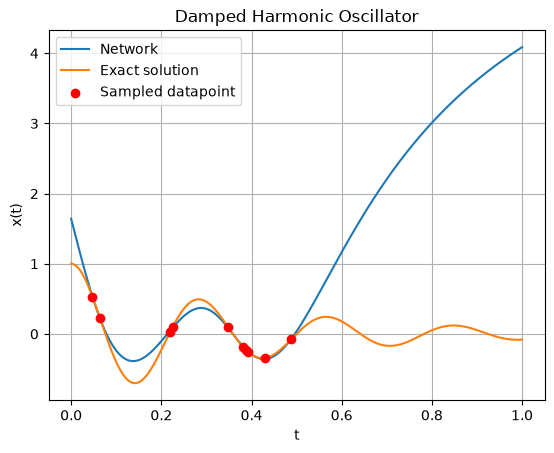

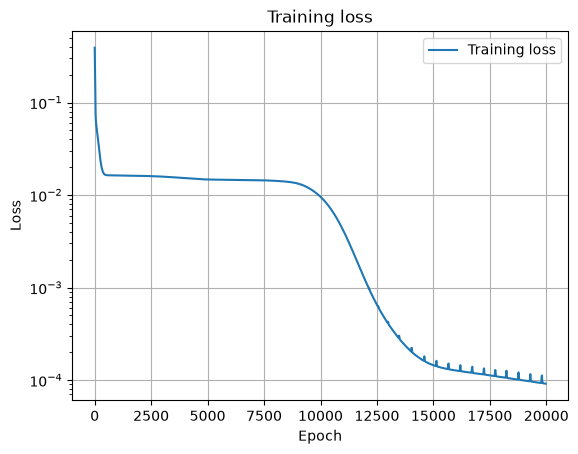

In [150]:
# Evaluation
net.eval()
t_test = torch.linspace(t0, 1.0, 10000).unsqueeze(1)

with torch.no_grad():
    x_pred = net(t_test)
plt.figure()
# Plot PINN approximation
plt.plot(t_test.numpy(), x_pred.numpy(), label="Network")

# Plot the exact analytical solution
plt.plot(t_test, x_sol(t_test), label="Exact solution")

# Datapoint
plt.scatter(t_data, x_data, color="red", label="Sampled datapoint", zorder=5)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid()
plt.title("Damped Harmonic Oscillator")
plt.legend()
plt.show()

# Moving average
window = 30
train_losses = np.convolve(train_losses, np.ones(window)/window, mode='valid')

plt.figure()
plt.plot(train_losses, label = "Training loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid()
plt.title("Training loss")
plt.legend()
plt.show()


## Task 2.3 — Physics-Informed Loss and Analytical Gradients

In [151]:
# Collocation points

N = 1000
t_col = np.linspace(t0, T, N)

# Initialize network parameters
M = 32 # number of neurons in hidden layer

W1 = rng.normal(0, 0.1, size=(M, 1))
b1 =np.zeros((M, 1))

W2 = rng.normal(0, 0.1, size=(1, M))
b2 =np.zeros((1, 1))

params = (W1, b1, W2, b2)

# Network
def z(t, params): # Hidden layer
    W1, b1, W2, b2 = params
    return np.tanh(W1 * t + b1)

def f(t, params): # f(t) (Output layer)
    W1, b1, W2, b2 = params
    return W2 @ z(t, params) + b2

# Network derivatives
def D(t, params):
    return np.diag((1 - z(t, params)**2).flatten())

def Q(t, params): 
    z_t = z(t, params)
    return np.diag((-2 * z_t * (1 - z_t**2)).flatten())

def df_dt(t, params): # f'(t)
    W1, b1, W2, b2 = params
    return W2 @ D(t, params) @ W1

def d2f_dt2(t, params): # f''(t)
    W1, b1, W2, b2 = params
    return W2 @ Q(t, params) @ (W1 * W1)

# Physics residual
def r_phys(t, params):
    return (d2f_dt2(t, params) + (mu/m) * df_dt(t, params) + (k/m) * f(t, params))

### PINN Loss Function

In [152]:
def L(params, lam_phys, lam_IC): # Loss function

    L_data = np.mean((f(np.ravel(t_data), params).ravel() - np.ravel(x_data))**2)

    L_phys = np.mean([r_phys(t, params).item()**2 for t in t_col])

    L_IC = ((f(0, params).item() - 1)**2 + df_dt(0, params).item()**2)

    Loss = L_data + lam_phys * L_phys + lam_IC * L_IC

    return Loss, L_data, L_phys, L_IC

### Analytical Weight Gradients

#### Gradients with Respect to the Weights

In [153]:
def dL_dW2(params, lam_phys, lam_IC):

    W1, b1, W2, b2 = params

    # Data loss gradient
    gradients = []

    for t, x in zip(np.ravel(t_data), np.ravel(x_data)): # Loops over all t_data and x_data pairs
        grad = (2 * (f(t, params).item() - x) * (z(t, params)).T)
        gradients.append(grad)

    dL_data_dW2 = np.mean(gradients, axis=0)

    # Physics loss gradient
    gradients = []

    for t in t_col: # Loops over all collocation points

        grad = (k/m) * (z(t, params)).T # (k/m)*df/dW2
        grad += (mu/m) * (D(t, params) @ W1).T # (mu/m)*df'/dW2
        grad += (Q(t, params) @ (W1 * W1)).T # df''/dW2
        grad *= 2 * r_phys(t, params).item()

        gradients.append(grad)

    dL_phys_dW2 = np.mean(gradients, axis=0)

    # Initial condition loss gradient
    dL_IC_dW2 = (2 * (f(0, params).item() - 1) * (z(0, params)).T) + (2 * df_dt(0, params).item() * (D(0, params) @ W1).T)

    # Total loss gradient
    dL_dW2 = (dL_data_dW2 + lam_phys * dL_phys_dW2 + lam_IC * dL_IC_dW2)

    return dL_dW2

In [154]:
def S(t, params):
    z_t = z(t, params)
    return np.diag(((6*z_t**2 - 2) * (1 - z_t**2)).flatten())

def dL_dW1(params, lam_phys, lam_IC):

    W1, b1, W2, b2 = params

    A = np.diag(W1.flatten())
    B = np.diag((W1 * W1).flatten())

    # Data loss gradient
    gradients = []

    for t, x in zip(np.ravel(t_data), np.ravel(x_data)): # Loops over all t_data and x_data pairs
        grad = (2 * (f(t, params).item() - x) * t * (W2 @ D(t, params)).T)
        gradients.append(grad)

    dL_data_dW1 = np.mean(gradients, axis=0)

    # Physics loss gradient
    gradients = []

    for t in t_col: # Loops over all collocation points

        grad = (k/m) * t * (W2 @ D(t, params)).T # (k/m)*df/dW1
        grad += (mu/m) * (W2 @ (D(t, params) + t * Q(t, params) @ A)).T # (mu/m)*df'/dW1
        grad += (W2 @ (2 * Q(t, params) @ A + t * S(t, params) @ B)).T # df''/dW1
        grad *= 2 * r_phys(t, params).item()

        gradients.append(grad)

    dL_phys_dW1 = np.mean(gradients, axis=0)

    # Initial condition loss gradient
    dL_IC_dW1 = (2 * df_dt(0, params).item() * (W2 @ D(0, params)).T)

    # Total loss gradient
    dL_dW1 = (dL_data_dW1 + lam_phys * dL_phys_dW1 + lam_IC * dL_IC_dW1)

    return dL_dW1

## Task 2.4 — Finite-Difference Gradient Verification

In [155]:
# Compare analytical gradient with finite difference approximation

lam_phys, lam_IC = 1e-3, 1.0 # Loss term weights

def fin_diff(L, params, param_idx=0, index=(0, 0), eps=1e-5):

    params_plus = list(params)
    params_minus = list(params)

    # Copy the parameter matrix being differentiated
    params_plus[param_idx] = params[param_idx].copy()
    params_minus[param_idx] = params[param_idx].copy()

    # Perturb selected weight
    params_plus[param_idx][index] += eps
    params_minus[param_idx][index] -= eps

    L_plus,_,_,_ = L(tuple(params_plus),lam_phys, lam_IC)
    L_minus,_,_,_ = L(tuple(params_minus),lam_phys, lam_IC)

    # Finite difference
    grad_numerical = (L_plus - L_minus) / (2 * eps)

    return grad_numerical

# M number of neurons in hidden layer
grad_numerical, grad_analytical = np.zeros(M), np.zeros(M)

# Calculate the partial derivatives for each index
for i in range(M):
    grad_numerical[i] = fin_diff(L, params, 0, (i,0))
    grad_analytical[i] = dL_dW1(params, lam_phys, lam_IC)[(i,0)]

print(f"Maximum absolute difference W1: {np.max(np.abs(grad_analytical - grad_numerical)):.3e}")

Maximum absolute difference W1: 2.569e-11


## Task 2.5 — Training with Analytical Gradients

#### Gradients with Respect to the Biases

In [156]:
def dL_db2(params, lam_phys, lam_IC):

    W1, b1, W2, b2 = params

    # Data loss gradient
    gradients = []

    for t, x in zip(np.ravel(t_data), np.ravel(x_data)): # Loops over all t_data and x_data pairs
        grad = (2 * (f(t, params).item() - x))
        gradients.append(grad)

    dL_data_db2 = np.mean(gradients, axis=0)

    # Physics loss gradient
    gradients = []

    for t in t_col: # Loops over all collocation points

        grad = (k/m) # (k/m)*df/db2
        grad *= 2 * r_phys(t, params).item()

        gradients.append(grad)

    dL_phys_db2 = np.mean(gradients, axis=0)

    # Initial condition loss gradient
    dL_IC_db2 = (2 * (f(0, params).item() - 1))

    # Total loss gradient
    dL_db2 = (dL_data_db2 + lam_phys * dL_phys_db2 + lam_IC * dL_IC_db2)

    return np.array([[dL_db2]])

In [157]:
def dL_db1(params, lam_phys, lam_IC):

    W1, b1, W2, b2 = params

    A = np.diag(W1.flatten())
    B = np.diag((W1 * W1).flatten())

    # Data loss gradient
    gradients = []

    for t, x in zip(np.ravel(t_data), np.ravel(x_data)): # Loops over all t_data and x_data pairs
        grad = (2 * (f(t, params).item() - x) * (W2 @ D(t, params)).T)
        gradients.append(grad)

    dL_data_db1 = np.mean(gradients, axis=0)

    # Physics loss gradient
    gradients = []

    for t in t_col: # Loops over all collocation points

        grad = (k/m)  * (W2 @ D(t, params)).T # (k/m)*df/db1
        grad += (mu/m) * (W2 @ Q(t, params) @ A).T # (mu/m)*df'/db1
        grad += (W2 @ S(t, params) @ B).T # df''/db1
        grad *= 2 * r_phys(t, params).item()

        gradients.append(grad)

    dL_phys_db1 = np.mean(gradients, axis=0)

    # Initial condition loss gradient
    dL_IC_db1 = ((2 * (f(0, params).item() - 1) * (W2 @ D(0, params))).T 
                + (2 * df_dt(0, params).item() * (W2 @ Q(0,params) @ A)).T
    )

    # Total loss gradient
    dL_db1 = (dL_data_db1 + lam_phys * dL_phys_db1 + lam_IC * dL_IC_db1)

    return dL_db1

### Training Configuration

#### Parameter Initialization

In [158]:
grad_L = (dL_dW1, dL_db1, dL_dW2, dL_db2)

# Xavier initilization
def init_weights():
    rng = np.random.default_rng(seed)
    M = 32

    limit = np.sqrt(6 / (1 + M))

    W1 = rng.uniform(-limit, limit, size=(M, 1))
    b1 = np.zeros((M, 1))

    W2 = rng.uniform(-limit, limit, size=(1, M))
    b2 = np.zeros((1, 1))

    params = (W1, b1, W2, b2)
    return params

# Network
def z(t, params): # Hidden layer
    W1, b1, W2, b2 = params
    return np.tanh(W1 * t + b1)

def f(t, params): # f(t) (Output layer)
    W1, b1, W2, b2 = params
    return W2 @ z(t, params) + b2

#### Preparing Parameters for SciPy Optimization

SciPy requires all parameters to be stored in one array, so we use `flatten()` to combine the weights and biases.

The `unflatten()` function converts them back to their original shapes, allowing us to use the same loss and gradient functions as before.

In [ ]:
params = init_weights()

# Save the original parameter shapes
shapes = [p.shape for p in params]
sizes = [p.size for p in params]

def flatten(params):
    return np.concatenate([p.ravel() for p in params])

def unflatten(flat):
    arrays = np.split(flat, np.cumsum(sizes)[:-1])
    return tuple(a.reshape(shape) for a, shape in zip(arrays, shapes))

def loss_flat(flat, lam_phys, lam_IC, return_terms=False):
    params = unflatten(flat)
    Loss, L_data, L_phys, L_IC =  L(params, lam_phys, lam_IC)
    if return_terms:
        return Loss, L_data, L_phys, L_IC

    return Loss

def gradient_flat(flat, lam_phys, lam_IC):
    params = unflatten(flat)

    gradients = [
        grad(params, lam_phys=lam_phys, lam_IC=lam_IC)
        for grad in grad_L
    ]

    return flatten(gradients)

#### Optimization Using Scipy "L-BFGS-B" Optimizer

We use SciPy's L-BFGS-B optimizer to train the network with our analytical gradients.

The helper functions calculate the loss and gradients, while the `callback` keeps track of the losses during training.

In [ ]:
from scipy.optimize import minimize
from time import perf_counter

params = init_weights()

# Loss term weights
lam_IC = 10.0
lam_phys = 1e-4

loss_history = []
start = perf_counter()

def callback(xk):
    Loss, L_data, L_phys, L_IC = loss_flat(xk, lam_phys, lam_IC, return_terms=True)
    
    loss_history.append(Loss)
    if len(loss_history) % 100 == 0:
        print(f"Iteration {len(loss_history):5d} | Loss: {Loss:.3e} | Data: {L_data:.3e} | Physics: {L_phys:.3e} | IC: {L_IC:.3e} | Total time: {perf_counter()-start:.1f} s")

result = minimize(
    fun=loss_flat,
    x0=flatten(params),
    args=(lam_phys, lam_IC),
    jac=gradient_flat,
    method="L-BFGS-B",
    callback=callback,
    options={"maxiter": 100}
)

trained_params = unflatten(result.x)

print(f"Total run time: {perf_counter()-start:.1f} sec.")
print("Success:", result.success)
print(f"Final loss: {result.fun:.3e}")
print("Iterations:", result.nit)
print("Message:", result.message)

Iteration   100 | Loss: 3.688e-01 | Data: 3.596e-02 | Physics: 3.064e+03 | IC: 2.640e-03 | Total time: 30.1 s
Total run time: 30.1 sec.
Success: False
Final loss: 3.688e-01
Iterations: 100
Message: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT


### Results and Loss Curves

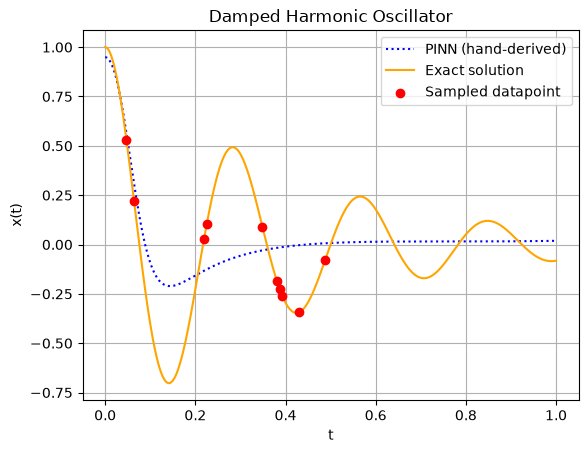

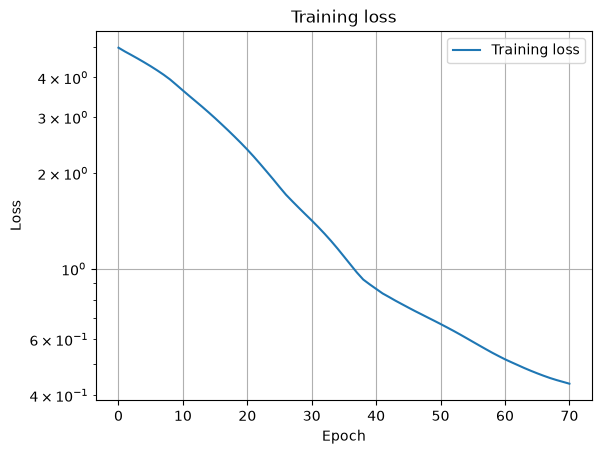

In [ ]:
# Evaluation
t_test = np.linspace(t0, T, 10000)
x_pred = f(t_test,trained_params).flatten()

plt.figure()
# Plot PINN approximation
plt.plot(t_test, x_pred, label="PINN (hand-derived)", linestyle=":", color="blue")

# Plot analytical solution
plt.plot(t_test, x_sol(t_test), label="Exact solution", color="orange")

# Datapoint
plt.scatter(t_data, x_data, color="red", label="Sampled datapoint", zorder=5)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid()
plt.title("Damped Harmonic Oscillator")
plt.legend()
plt.show()


# Moving average
window = 30
numpy_losses = np.convolve(loss_history, np.ones(window)/window, mode='valid')

plt.figure()
plt.plot(numpy_losses, label = "Training loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid()
plt.title("Training loss")
plt.legend()
plt.show()

## Task 2.6 — Comparison with PyTorch Autograd

In [ ]:
# Define initial conditions
x_t0_true = torch.tensor([[1.0]])
v_t0_true = torch.tensor([[0.0]])

# Initial conditions (convert to float)
x0_true = x_t0_true.squeeze().item()
v0_true = v_t0_true.squeeze().item()
y0 = [x0_true, v0_true]  # x(0), v(0)

# Data points
t_data_tensor = torch.from_numpy(t_data).reshape(-1, 1)
x_data_tensor = torch.from_numpy(x_data).reshape(-1, 1)

# Collocation points
t_col_tensor = torch.from_numpy(t_col).reshape(-1, 1).requires_grad_(True)

#### Matching the Initial Parameters

We start both implementations with the same weights and biases.

We use `copy_parameters()` to copy the NumPy parameters into the PyTorch network.

In [ ]:
def copy_parameters(params, pinn):
    W1, b1, W2, b2 = params

    with torch.no_grad():
        pinn.model[0].weight.copy_(torch.from_numpy(W1))
        pinn.model[0].bias.copy_(torch.from_numpy(b1.flatten()))

        pinn.model[2].weight.copy_(torch.from_numpy(W2))
        pinn.model[2].bias.copy_(torch.from_numpy(b2.flatten()))

### PINN Loss and Autograd Gradients

We calculate the same three loss terms as in the NumPy implementation.

The difference is that we now use PyTorch autograd to calculate the derivatives instead of using our analytical expressions.

In [171]:
pinn = Net(1,1,[32]) # Initialize PINN

params = init_weights()
copy_parameters(params, pinn)

# Define optimizer
# optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-3)
optimizer = torch.optim.SGD(pinn.parameters(), lr=1e-3)

# Loss term weights
lam_IC = 10.0
lam_phys = 1e-4

# Reset gradients from the previous iteration
optimizer.zero_grad()

def compute_pinn_loss(pinn, lam_phys, lam_IC, return_terms=False):

    x = pinn(t_col_tensor)

    # Compute velocity and acceleration
    v = torch.autograd.grad(
        x, t_col_tensor,
        grad_outputs=torch.ones_like(x),
        create_graph=True
    )[0]

    a = torch.autograd.grad(
        v, t_col_tensor,
        grad_outputs=torch.ones_like(v),
        create_graph=True
    )[0]

    # physics loss
    residual = a + (mu/m) * v + (k/m) * x 
    physic_loss = torch.mean(residual**2)

    # IC loss
    t0_tensor = torch.tensor([[t0]], requires_grad=True)
    x_t0 = pinn(t0_tensor)
    v_t0 = torch.autograd.grad(
        x_t0, t0_tensor,
        grad_outputs=torch.ones_like(x_t0),
        create_graph=True
    )[0]

    ic_loss = torch.mean((x_t0 - x_t0_true)**2 + (v_t0 - v_t0_true)**2)

    # Datapoint loss
    x_data_pred = pinn(t_data_tensor)

    data_loss = torch.mean((x_data_pred - x_data_tensor)**2)

    # Total loss
    loss = data_loss + lam_phys * physic_loss + lam_IC * ic_loss

    if return_terms:
        return loss, data_loss, physic_loss, ic_loss

    return loss

# compute gradients given loss
loss = compute_pinn_loss(pinn, lam_phys, lam_IC)

loss.backward()

### Gradient Comparison at Initialization

In [172]:

# Analytical gradients
grad_W1_analytical = dL_dW1(params, lam_phys, lam_IC)
grad_W2_analytical = dL_dW2(params, lam_phys, lam_IC)

# Autograd gradients
grad_W1_torch = pinn.model[0].weight.grad.detach().numpy()
grad_W2_torch = pinn.model[2].weight.grad.detach().numpy()

# Relative L2-errors
rel_W1 = np.linalg.norm(grad_W1_analytical - grad_W1_torch) / np.linalg.norm(grad_W1_torch)

rel_W2 = np.linalg.norm(grad_W2_analytical - grad_W2_torch) / np.linalg.norm(grad_W2_torch)

print(f"Relative L2-error W1 (%): {rel_W1*100:.3e}%")
print(f"Relative L2-error W2 (%): {rel_W2*100:.3e}%")

Relative L2-error W1 (%): 2.651e-14%
Relative L2-error W2 (%): 2.786e-14%


### SciPy Optimization with PyTorch Autograd

We train the PyTorch network using the same SciPy optimizer as before, to make it as comparable as possible.

This time, the gradients are calculated using autograd. This allows us to compare the two implementations without changing the optimizer.

We also record the losses during training to compare the loss curves afterward.

In [ ]:
# Use the same initial parameters as the NumPy implementation
pinn = Net(1, 1, [32])

params = init_weights()
copy_parameters(params, pinn)

torch_params = list(pinn.parameters())

# Loss term weights
lam_IC = 10.0
lam_phys = 1e-4

# Transfer a flat parameter vector into the PyTorch model
def load_parameters(flat):
    offset = 0
    with torch.no_grad():
        for p in torch_params:
            n = p.numel()
            values = torch.from_numpy(flat[offset:offset+n])
            p.copy_(values.reshape_as(p))
            offset += n

# Function passed to SciPy
def torch_objective(flat):
    load_parameters(flat)
    pinn.zero_grad(set_to_none=True)

    loss = compute_pinn_loss(pinn, lam_phys, lam_IC)
    loss.backward()

    gradients = np.concatenate([
        p.grad.detach().cpu().numpy().ravel()
        for p in torch_params
    ])

    return loss.item(), gradients

def callback_torch(xk):
    # Load current optimizer parameters
    load_parameters(xk)

    # Calculate all loss terms
    Loss, L_data, L_phys, L_IC = compute_pinn_loss(
        pinn, lam_phys, lam_IC, return_terms=True
    )
        
    loss_history.append(Loss.detach().numpy())
    if len(loss_history) % 100 == 0:
        print(f"Iteration {len(loss_history):5d} | Loss: {Loss:.3e} | Data: {L_data:.3e} | Physics: {L_phys:.3e} | IC: {L_IC:.3e} | Total time: {perf_counter()-start:.1f} s")

loss_history = []
start = perf_counter()

result_torch = minimize(
    fun=torch_objective,
    x0=flatten(params),
    jac=True,
    method="L-BFGS-B",
    callback=callback_torch,
    options={"maxiter": 1000}
)

# Load the final optimized parameters into PyTorch
load_parameters(result_torch.x)

print(f"Total run time: {perf_counter()-start:.1f} sec.")
print("Success:", result_torch.success)
print(f"Final loss: {result_torch.fun:.3e}")
print("Iterations:", result_torch.nit)
print("Message:", result_torch.message)

Iteration   100 | Loss: 3.274e-01 | Data: 4.325e-02 | Physics: 2.724e+03 | IC: 1.182e-03 | Total time: 0.2 s
Total run time: 0.2 sec.
Success: False
Final loss: 3.688e-01
Iterations: 100
Message: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT


### Comparison of Predictions and Loss Curves

C:\Users\oloms\AppData\Local\Temp\ipykernel_18160\3175266171.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  x_sol = lambda t : np.exp(-d*t)*(2*A*np.cos(phi + w*t))


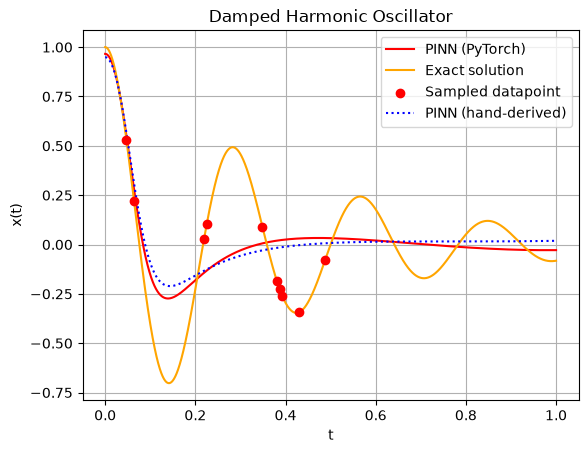

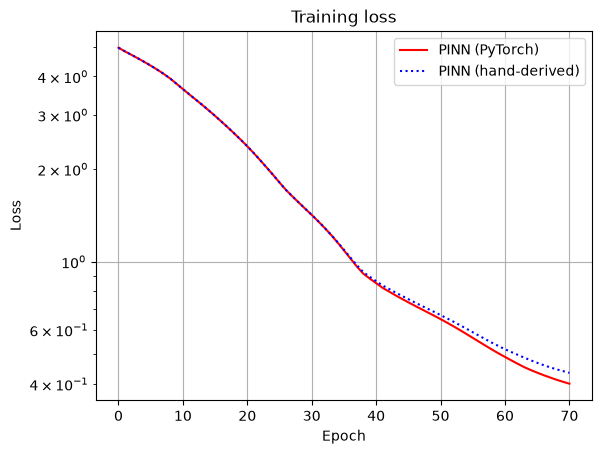

In [ ]:
# Evaluate trained model on the full time interval
pinn.eval()
t_test = torch.linspace(t0, T, 10000).unsqueeze(1)

with torch.no_grad():
    x_pred = pinn(t_test)
plt.figure()
# Plot PINN approximation
plt.plot(t_test.numpy(), x_pred.numpy(), label="PINN (PyTorch)", color="red")

# Plot the exact analytical solution
plt.plot(t_test, x_sol(t_test), label="Exact solution", color="orange")

# Datapoint
plt.scatter(t_data, x_data, color="red", label="Sampled datapoint", zorder=5)

# Evaluation Numpy
t_test = np.linspace(t0, T, 10000)
x_pred = f(t_test, trained_params).flatten()

# Plot PINN approximation
plt.plot(t_test, x_pred, label="PINN (hand-derived)", linestyle=':', color="blue")

plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid()
plt.title("Damped Harmonic Oscillator")
plt.legend()
plt.show()

# Moving average
window = 30
torch_losses = np.convolve(loss_history, np.ones(window)/window, mode='valid')

plt.figure()
plt.plot(torch_losses, label="PINN (PyTorch)", color="red")
plt.plot(numpy_losses, label="PINN (hand-derived)", linestyle=':', color="blue")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid()
plt.title("Training loss")
plt.legend()
plt.show()

## Task 2.7 — Soft and Hard Enforcement of Initial Conditions

### Soft Enforcement

In [ ]:
pinn = Net(1,1,[32]) # Initialize PINN

params = init_weights()
copy_parameters(params, pinn)

# Define optimizer
optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-3)
# optimizer = torch.optim.SGD(pinn.parameters(), lr=1e-3)

# Loss term weights
lam_IC = 10.0
lam_phys = 1e-4

# number of training passses
EPOCHS = 50_000
# store loss
train_losses = []
start = perf_counter()

# training loop
for e in range(EPOCHS):
    
    # Reset gradients from the previous iteration
    optimizer.zero_grad()

    loss, data_loss, physic_loss, ic_loss = compute_pinn_loss(pinn, lam_phys, lam_IC, return_terms=True)

    # compute gradients given loss
    loss.backward()

    # update the parameters given the computed gradients
    optimizer.step()
    
    # store training loss
    train_losses.append(loss.detach().numpy())
    
    if (e+1) % (EPOCHS//10) == 0:
            print(f"Epoch {(e+1):5d} | Loss: {loss:.3e} | Data: {data_loss:.3e} | Physics: {physic_loss:.3e} | IC: {ic_loss:.3e} | Total time: {perf_counter()-start:.1f} s")

# Moving average
window = 30
torch_losses = np.convolve(train_losses, np.ones(window)/window, mode='valid')

Epoch  5000 | Loss: 1.432e+00 | Data: 5.003e-02 | Physics: 1.082e+04 | IC: 3.002e-02
Epoch 10000 | Loss: 3.694e-01 | Data: 6.722e-02 | Physics: 2.691e+03 | IC: 3.303e-03
Epoch 15000 | Loss: 1.174e-01 | Data: 2.490e-02 | Physics: 8.918e+02 | IC: 3.276e-04
Epoch 20000 | Loss: 6.036e-02 | Data: 9.390e-03 | Physics: 5.044e+02 | IC: 5.318e-05
Epoch 25000 | Loss: 5.160e-02 | Data: 6.355e-03 | Physics: 4.497e+02 | IC: 2.790e-05
Epoch 30000 | Loss: 4.989e-02 | Data: 5.800e-03 | Physics: 4.381e+02 | IC: 2.771e-05
Epoch 35000 | Loss: 4.892e-02 | Data: 5.505e-03 | Physics: 4.314e+02 | IC: 2.693e-05
Epoch 40000 | Loss: 4.819e-02 | Data: 5.318e-03 | Physics: 4.261e+02 | IC: 2.613e-05
Epoch 45000 | Loss: 4.753e-02 | Data: 5.182e-03 | Physics: 4.209e+02 | IC: 2.536e-05
Epoch 50000 | Loss: 4.689e-02 | Data: 5.056e-03 | Physics: 4.157e+02 | IC: 2.569e-05


### Hard Enforcement

In [ ]:
pinn2 = Net(1,1,[32]) # Initialize PINN

params = init_weights()
copy_parameters(params, pinn2)

# Define optimizer
optimizer = torch.optim.Adam(pinn2.parameters(), lr=1e-3)
# optimizer = torch.optim.SGD(pinn2.parameters(), lr=1e-3)

# Loss term weights
lam_IC = 10.0
lam_phys = 1e-4

# number of training passses
EPOCHS = 50_000
# store loss
train_losses = []
start = perf_counter()

# training loop
for e in range(EPOCHS):
    
    # Reset gradients from the previous iteration
    optimizer.zero_grad()

    x = 1 + (t_col_tensor)**2 * pinn2(t_col_tensor)

    # Compute velocity and acceleration
    v = torch.autograd.grad(
        x, t_col_tensor,
        grad_outputs=torch.ones_like(x),
        create_graph=True
    )[0]

    a = torch.autograd.grad(
        v, t_col_tensor,
        grad_outputs=torch.ones_like(v),
        create_graph=True
    )[0]

    # physics loss
    residual = a + (mu/m) * v + (k/m) * x 
    physic_loss = torch.mean(residual**2)

    # IC loss
    t0_tensor = torch.tensor([[t0]], requires_grad=True)
    x_t0 = 1 + t0_tensor**2 * pinn2(t0_tensor)
    v_t0 = torch.autograd.grad(
        x_t0, t0_tensor,
        grad_outputs=torch.ones_like(x_t0),
        create_graph=True
    )[0]

    ic_loss = torch.mean((x_t0 - x_t0_true)**2 + (v_t0 - v_t0_true)**2)

    # Datapoint loss
    x_data_pred = 1 + t_data_tensor**2 * pinn2(t_data_tensor)

    data_loss = torch.mean((x_data_pred - x_data_tensor)**2)

    # Total loss
    loss = data_loss + lam_phys * physic_loss

    # compute gradients given loss
    loss.backward()

    # update the parameters given the computed gradients
    optimizer.step()
    
    # store training loss
    train_losses.append(loss.detach().numpy())
    
    if (e+1) % (EPOCHS//10) == 0:
        print(f"Epoch {(e+1):5d} | Loss: {loss:.3e} | Data: {data_loss:.3e} | Physics: {physic_loss:.3e} | IC: {0.0:.3e} | Total time: {perf_counter()-start:.1f} s")

Epoch  5000 | Loss: 2.758e+00 | Data: 8.328e-02 | Physics: 2.675e+04 | IC: 0.000e+00
Epoch 10000 | Loss: 1.270e+00 | Data: 9.401e-02 | Physics: 1.176e+04 | IC: 0.000e+00
Epoch 15000 | Loss: 5.804e-01 | Data: 8.174e-02 | Physics: 4.986e+03 | IC: 0.000e+00
Epoch 20000 | Loss: 3.142e-01 | Data: 5.007e-02 | Physics: 2.642e+03 | IC: 0.000e+00
Epoch 25000 | Loss: 1.883e-01 | Data: 3.009e-02 | Physics: 1.582e+03 | IC: 0.000e+00
Epoch 30000 | Loss: 1.356e-01 | Data: 2.076e-02 | Physics: 1.148e+03 | IC: 0.000e+00
Epoch 35000 | Loss: 1.093e-01 | Data: 1.667e-02 | Physics: 9.263e+02 | IC: 0.000e+00
Epoch 40000 | Loss: 8.995e-02 | Data: 1.403e-02 | Physics: 7.591e+02 | IC: 0.000e+00
Epoch 45000 | Loss: 7.944e-02 | Data: 1.247e-02 | Physics: 6.697e+02 | IC: 0.000e+00
Epoch 50000 | Loss: 6.827e-02 | Data: 1.041e-02 | Physics: 5.787e+02 | IC: 0.000e+00


### Comparison of Results

### Network Output and Time Derivatives

C:\Users\oloms\AppData\Local\Temp\ipykernel_18160\3175266171.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  x_sol = lambda t : np.exp(-d*t)*(2*A*np.cos(phi + w*t))


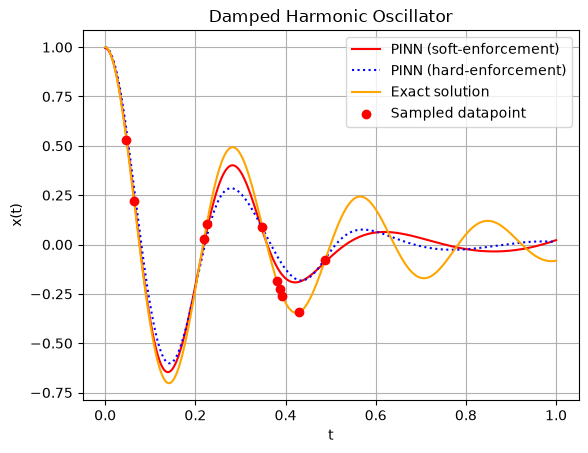

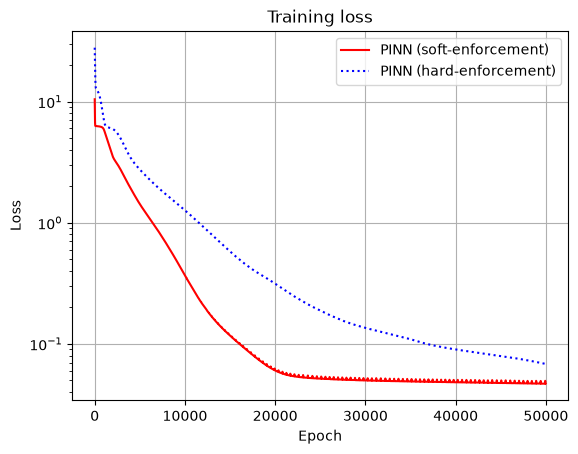

In [188]:
# Evaluate trained model on the full time interval
pinn2.eval()
t_test = torch.linspace(t0, T, 10000).unsqueeze(1)

# Evaluation
pinn.eval()

with torch.no_grad():
    x_pred = pinn(t_test)

plt.figure()
# Plot PINN approximation
plt.plot(t_test, x_pred, label="PINN (soft-enforcement)", color="red")

with torch.no_grad():
    x_pred = 1 + t_test**2 * pinn2(t_test)

# Plot PINN approximation
plt.plot(t_test.numpy(), x_pred.numpy(), label="PINN (hard-enforcement)", linestyle=':', color="blue")

# Plot the exact analytical solution
plt.plot(t_test, x_sol(t_test), label="Exact solution", color="orange")

# Datapoint
plt.scatter(t_data, x_data, color="red", label="Sampled datapoint", zorder=5)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid()
plt.title("Damped Harmonic Oscillator")
plt.legend()
plt.show()

# Moving average
window = 30
torch2_losses = np.convolve(train_losses, np.ones(window)/window, mode='valid')

plt.figure()
plt.plot(torch_losses, label="PINN (soft-enforcement)", color="red")
plt.plot(torch2_losses, label="PINN (hard-enforcement)", linestyle=':', color="blue")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid()
plt.title("Training loss")
plt.legend()
plt.show()